# Stage 2 — Gap-Coverage Atlas

**The single most important diagnostic in the whole project.** It decides whether daily forecasting is physically possible in this region, or whether we have to drop the target to a 3-day rolling composite.

## Why this comes before any modelling
Winter convective blooms in the Malta–Sicily Channel happen *in exactly the cloudiest season*. If you only discover that coverage is poor after training models, you'll have wasted weeks. Front-load the pain here.

## What we measure
For each day, valid-pixel coverage is the number of valid QC-filtered CHL retrievals divided by the number of pixels in the observable target domain created by Notebook 01. Land and permanently unavailable pixels are excluded from the denominator.

The 25% threshold is a sampling-feasibility heuristic, not proof that operational daily forecasting is possible. We also record zero-coverage days, low-coverage runs, and forecast-pair availability.

## 2.1 — Load the cube from Stage 1

Reuse the file we produced in `01-Data-Acquisition.ipynb`. We don't recompute or re-download anything here.

In [1]:
from pathlib import Path

import numpy as np
import xarray as xr

RAW_DIR  = Path("data/raw")
FIG_DIR  = Path("figs")
PROC_DIR = Path("data/processed")

FIG_DIR.mkdir(parents=True, exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)

CHL_PATH = RAW_DIR / "chl_malta_2021_2023.nc"
DOMAIN_PATH = PROC_DIR / "chl_target_domain.nc"

assert CHL_PATH.exists(), (
    f"Missing {CHL_PATH} — run Notebook 01 first."
)
assert DOMAIN_PATH.exists(), (
    f"Missing {DOMAIN_PATH} — rerun Notebook 01 Gate 1."
)

ds  = xr.open_dataset(
    CHL_PATH, 
    chunks={"time": 50}
)

domain_ds = xr.open_dataset(DOMAIN_PATH)

target_domain = (
    domain_ds["target_domain"]
    .astype(bool)
)

chl_raw = ds["CHL"]

valid_min = float(
    chl_raw.attrs.get("valid_min", 0.0)
)
valid_max = float(
    chl_raw.attrs.get("valid_max", np.inf)
)

chl = chl_raw.where(
    (chl_raw >= valid_min)
    & (chl_raw <= valid_max)
)

# Require exact coordinate agreement with Notebook 01.
chl, target_domain = xr.align(
    chl,
    target_domain,
    join="exact",
)

assert target_domain.dims == (
    "latitude",
    "longitude",
)

n_domain_pixels = int(
    target_domain.sum().item()
)

DECISION_THRESHOLD = 0.25

print(f"Loaded CHL: {dict(chl.sizes)}")
print(
    f"Time: {str(chl.time.values.min())[:10]} "
    f"→ {str(chl.time.values.max())[:10]}"
)
print(f"Target-domain pixels: {n_domain_pixels:,}")
print(
    f"Decision threshold: "
    f"{DECISION_THRESHOLD * 100:.1f}%"
)

Loaded CHL: {'time': 1095, 'latitude': 198, 'longitude': 272}
Time: 2021-01-01 → 2023-12-31
Target-domain pixels: 46,158
Decision threshold: 25.0%


## 2.2 — Daily valid-pixel fraction

Count valid CHL retrievals within the observable target-domain mask and divide by the number of pixels in that mask—not by the full rectangular grid. The daily table also records zero-coverage days, days below the 25% sampling threshold, and the longest runs of each condition.


In [2]:
import pandas as pd

spatial_dims = ["latitude", "longitude"]

valid_mask = (
    chl.notnull()
    & target_domain
)

valid_pixels_per_day = (
    valid_mask
    .sum(dim=spatial_dims)
    .compute()
    .to_series()
    .astype(int)
    .rename("valid_pixels")
)

valid_per_day = (
    valid_pixels_per_day
    / n_domain_pixels
).rename("valid_frac")

coverage_daily = pd.concat(
    [
        valid_pixels_per_day,
        valid_per_day
    ],
    axis=1
)

coverage_daily["domain_pixels"] = (
    n_domain_pixels
)

coverage_daily.index.name = "time"

def longest_true_run(values) -> int:
    longest = 0
    current = 0

    for value in values:
        if bool(value):
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest

zero_coverage = valid_per_day == 0

below_threshold = (
    valid_per_day < DECISION_THRESHOLD
)

n_zero_days = int(zero_coverage.sum())
n_below_threshold_days = int(
    below_threshold.sum()
)

max_zero_run = longest_true_run(
    zero_coverage.values
)

max_below_threshold_run = longest_true_run(
    below_threshold.values
)

print(
    f"Daily coverage: "
    f"min={valid_per_day.min() * 100:.1f}%, "
    f"median={valid_per_day.median() * 100:.1f}%, "
    f"mean={valid_per_day.mean() * 100:.1f}%, "
    f"max={valid_per_day.max() * 100:.1f}%"
)

print(f"Zero-coverage days: {n_zero_days}")
print(
    "Longest zero-coverage run: "
    f"{max_zero_run} days"
)
print(
    f"Days below {DECISION_THRESHOLD * 100:.0f}%: "
    f"{n_below_threshold_days}"
)
print(
    "Longest below-threshold run: "
    f"{max_below_threshold_run} days"
)

coverage_daily.describe().round(3)

Daily coverage: min=0.0%, median=65.6%, mean=56.7%, max=99.1%
Zero-coverage days: 87
Longest zero-coverage run: 4 days
Days below 25%: 302
Longest below-threshold run: 13 days


,valid_pixels,valid_frac,domain_pixels
count,1095.000,1095.000,1095.0
mean,26186.621,0.567,46158.0
std,16586.705,0.359,0.0
min,0.000,0.000,46158.0
25%,9535.000,0.207,46158.0
50%,30290.000,0.656,46158.0
75%,42349.500,0.917,46158.0
max,45747.000,0.991,46158.0


In [3]:
pair_rows = []

valid = chl.notnull()
n_time = chl.sizes["time"]

for horizon in range(1, 8):
    # Origin validity at time t.
    now_valid = valid.isel(
        time=slice(None, -horizon)
    )

    # Target validity at time t+h. Reassign the time coordinate
    # so xarray compares corresponding origin/target rows.
    future_valid = (
        valid
        .isel(time=slice(horizon, None))
        .assign_coords(time=now_valid.time)
    )

    total_pairs = (
        (n_time - horizon)
        * n_domain_pixels
    )

    target_observed = int(
        (
            future_valid
            & target_domain
        )
        .sum()
        .compute()
    )

    both_observed = int(
        (
            now_valid
            & future_valid
            & target_domain
        )
        .sum()
        .compute()
    )

    target_observed_while_now_missing = int(
        (
            (~now_valid)
            & future_valid
            & target_domain
        )
        .sum()
        .compute()
    )

    pair_rows.append(
        {
            "horizon": horizon,
            "total_domain_pairs": total_pairs,
            "target_observed_pairs": target_observed,
            "both_t0_and_target_observed_pairs": both_observed,
            "target_observed_fraction": (
                target_observed / total_pairs
            ),
            "both_observed_fraction": (
                both_observed / total_pairs
            ),
            "share_of_observed_targets_with_t0_missing": (
                target_observed_while_now_missing
                / target_observed
            ),
        }
    )

pair_availability = pd.DataFrame(pair_rows)

pair_availability.to_csv(
    PROC_DIR / "coverage_pair_availability.csv",
    index=False,
)

print(
    pair_availability[
        [
            "horizon",
            "target_observed_fraction",
            "both_observed_fraction",
            "share_of_observed_targets_with_t0_missing",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

 horizon  target_observed_fraction  both_observed_fraction  share_of_observed_targets_with_t0_missing
       1                    0.5673                  0.3897                                     0.3131
       2                    0.5671                  0.3542                                     0.3753
       3                    0.5670                  0.3473                                     0.3874
       4                    0.5671                  0.3475                                     0.3873
       5                    0.5671                  0.3430                                     0.3951
       6                    0.5668                  0.3425                                     0.3958
       7                    0.5672                  0.3431                                     0.3951


## 2.3 — Monthly and year-month coverage summaries

Summarise daily target-domain coverage by calendar month and by individual year-month. The outputs include mean, standard deviation, minimum, median, and day count, while the 12-month climatology supplies the atlas plot. Daily, monthly, year-month, and paired-day availability artifacts are persisted for later checks.


In [4]:
monthly_stats = (
    valid_per_day
    .groupby(valid_per_day.index.month)
    .agg(
        [
            "mean",
            "std",
            "min",
            "median",
            "count",
        ]
    )
)

monthly_stats.index.name = "month"

monthly_stats = monthly_stats.rename(
    columns={
        "mean": "coverage_mean_fraction",
        "std": "coverage_std_fraction",
        "min": "coverage_min_fraction",
        "median": "coverage_median_fraction",
        "count": "n_days",
    }
)

monthly_stats["coverage_mean_pct"] = (
    monthly_stats["coverage_mean_fraction"]
    * 100
)

monthly_pct = (
    monthly_stats["coverage_mean_pct"]
)

year_month = (
    valid_per_day
    .resample("MS")
    .agg(
        [
            "mean",
            "std",
            "min",
            "median",
            "count",
        ]
    )
)

year_month = year_month.rename(
    columns={
        "mean": "coverage_mean_fraction",
        "std": "coverage_std_fraction",
        "min": "coverage_min_fraction",
        "median": "coverage_median_fraction",
        "count": "n_days",
    }
)

coverage_daily.to_parquet(
    PROC_DIR / "coverage_daily.parquet"
)

monthly_stats.to_csv(
    PROC_DIR / "coverage_monthly.csv"
)

year_month.to_csv(
    PROC_DIR / "coverage_year_month.csv"
)

print(
    "Mean daily target-domain coverage by month:"
)

print(
    monthly_pct
    .round(1)
    .rename("coverage_%")
    .to_string()
)

Mean daily target-domain coverage by month:
month
1     47.5
2     57.6
3     55.2
4     49.1
5     53.9
6     55.2
7     74.1
8     72.5
9     54.4
10    62.4
11    51.5
12    47.0


## 2.4 — Plot it

Bar chart of monthly mean coverage, with the 25% decision threshold drawn in red.

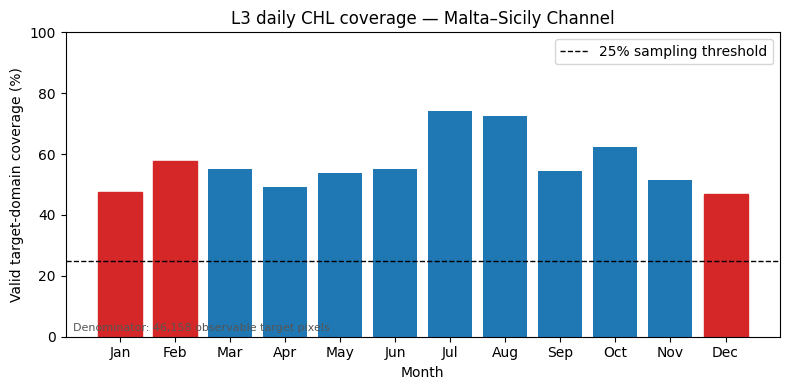

Saved: figs\02_coverage_atlas.png


In [5]:
import matplotlib.pyplot as plt

MONTH_LABELS = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec",
]

fig, ax = plt.subplots(
    figsize=(8, 4)
)

bars = ax.bar(
    MONTH_LABELS,
    monthly_pct.values,
    color=["#1f77b4"] * 12,
)

# Highlight December, January and February.
for index in (11, 0, 1):
    bars[index].set_color("#d62728")

ax.axhline(
    DECISION_THRESHOLD * 100,
    color="black",
    linestyle="--",
    linewidth=1,
    label=(
        f"{DECISION_THRESHOLD * 100:.0f}% "
        "sampling threshold"
    ),
)

ax.set_ylabel(
    "Valid target-domain coverage (%)"
)
ax.set_xlabel("Month")
ax.set_title(
    "L3 daily CHL coverage — Malta–Sicily Channel"
)
ax.set_ylim(0, 100)
ax.legend(loc="upper right")

ax.text(
    0.01,
    0.02,
    (
        f"Denominator: {n_domain_pixels:,} "
        "observable target pixels"
    ),
    transform=ax.transAxes,
    fontsize=8,
    color="#555555",
)

plt.tight_layout()

COVERAGE_FIG = (
    FIG_DIR / "02_coverage_atlas.png"
)

plt.savefig(
    COVERAGE_FIG,
    dpi=150,
)

plt.show()

print(f"Saved: {COVERAGE_FIG}")

---
## Validation Gate 2 — Choose the target mode

Compute the day-weighted December–January–February coverage over the observable target domain and compare it with the 25% sampling-feasibility threshold. If it passes, retain daily targets. If it fails, Notebook 4 must use a forward three-day linear-CHL mean over `t+h` through `t+h+2`, requiring at least two observed days before applying `log10`.

The gate also reports complete winter seasons and zero/low-coverage runs, then writes both `coverage_decision.json` and the compatibility text file. This is a sampling decision, not evidence that forecasts are accurate when current CHL is missing.


In [6]:
import json

winter_months = [12, 1, 2]

winter_mask = (
    valid_per_day.index.month.isin(
        winter_months
    )
)

winter_daily = valid_per_day.loc[
    winter_mask
]

# Day-weighted DJF mean rather than giving each month
# exactly the same weight.
winter_cov = float(
    winter_daily.mean()
)

winter_zero_days = int(
    (winter_daily == 0).sum()
)

winter_below_threshold_days = int(
    (
        winter_daily
        < DECISION_THRESHOLD
    ).sum()
)

# Complete Dec–Jan–Feb seasons only.
winter_frame = winter_daily.to_frame(
    name="valid_frac"
)

winter_frame["season_year"] = (
    winter_frame.index.year
    + (
        winter_frame.index.month == 12
    ).astype(int)
)

winter_by_season = (
    winter_frame
    .groupby("season_year")["valid_frac"]
    .agg(["mean", "count"])
)

complete_winters = winter_by_season[
    winter_by_season["count"] >= 80
]

print(
    "Winter (DJF) day-weighted target-domain "
    f"coverage: {winter_cov * 100:.1f}%"
)

print()
print("Complete winter seasons:")

print(
    (
        complete_winters["mean"] * 100
    )
    .round(1)
    .rename("coverage_%")
    .to_string()
)

print()
print(
    f"Winter zero-coverage days: "
    f"{winter_zero_days}"
)
print(
    f"Winter days below threshold: "
    f"{winter_below_threshold_days}"
)

if winter_cov >= DECISION_THRESHOLD:
    decision = "DAILY"

    print()
    print("DECISION: DAILY target.")
    print(
        "The sampling-feasibility threshold is met."
    )
    print(
        "This does not prove performance when current "
        "CHL is missing; that must be tested separately."
    )

else:
    decision = "3-DAY COMPOSITE"

    print()
    print(
        "DECISION: FUTURE 3-DAY COMPOSITE target."
    )
    print(
        "Notebook 04 must define target_h as the "
        "linear-space mean of CHL at "
        "t+h, t+h+1 and t+h+2."
    )
    print(
        "Require at least two observed days, then "
        "apply log10 after compositing."
    )
    print(
        "Do not construct a trailing rolling mean "
        "before shifting; that would let the target "
        "window overlap the forecast origin."
    )

decision_record = {
    "decision": decision,
    "decision_threshold_fraction": (
        DECISION_THRESHOLD
    ),
    "winter_djf_coverage_fraction": (
        winter_cov
    ),
    "coverage_denominator": (
        "observable target-domain pixels"
    ),
    "domain_pixels": n_domain_pixels,
    "zero_coverage_days": n_zero_days,
    "below_threshold_days": (
        n_below_threshold_days
    ),
    "longest_zero_coverage_run_days": (
        max_zero_run
    ),
    "longest_below_threshold_run_days": (
        max_below_threshold_run
    ),
    "winter_zero_coverage_days": (
        winter_zero_days
    ),
    "winter_below_threshold_days": (
        winter_below_threshold_days
    ),
    "composite_definition_if_triggered": {
        "window": "t+h through t+h+2",
        "space": "linear CHL",
        "minimum_observed_days": 2,
        "log_transform": "after compositing",
    },
}

DECISION_JSON = (
    PROC_DIR / "coverage_decision.json"
)

with open(
    DECISION_JSON,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        decision_record,
        file,
        indent=2,
    )

# Keep the text file temporarily for compatibility with
# the current Notebook 04. Notebook 04 should later move
# to the JSON record.
DECISION_TXT = (
    PROC_DIR / "coverage_decision.txt"
)

with open(
    DECISION_TXT,
    "w",
    encoding="utf-8",
) as file:
    file.write(f"{decision}\n")
    file.write(
        "winter_djf_coverage_pct="
        f"{winter_cov * 100:.2f}\n"
    )
    file.write(
        "denominator=observable_target_domain\n"
    )

required_outputs = [
    PROC_DIR / "coverage_daily.parquet",
    PROC_DIR / "coverage_monthly.csv",
    PROC_DIR / "coverage_year_month.csv",
    PROC_DIR / "coverage_pair_availability.csv",
    DECISION_JSON,
    DECISION_TXT,
    COVERAGE_FIG,
]

missing_outputs = [
    str(path)
    for path in required_outputs
    if not path.exists()
]

if missing_outputs:
    raise RuntimeError(
        "Gate 2 outputs are missing:\n- "
        + "\n- ".join(missing_outputs)
    )

assert 0 <= winter_cov <= 1
assert decision in {
    "DAILY",
    "3-DAY COMPOSITE",
}

print()
print("Gate 2 PASSED.")
print(f"Decision saved to: {DECISION_JSON}")

Winter (DJF) day-weighted target-domain coverage: 50.5%

Complete winter seasons:
season_year
2022    51.0
2023    54.5

Winter zero-coverage days: 9
Winter days below threshold: 78

DECISION: DAILY target.
The sampling-feasibility threshold is met.
This does not prove performance when current CHL is missing; that must be tested separately.

Gate 2 PASSED.
Decision saved to: data\processed\coverage_decision.json


### Gate 2 checklist

- [ ] `figs/02_coverage_atlas.png` is readable.
- [ ] `coverage_daily.parquet`, `coverage_monthly.csv`, `coverage_year_month.csv`, and `coverage_pair_availability.csv` exist.
- [ ] `coverage_decision.json` records the DJF coverage, denominator, threshold, and target decision.
- [ ] Notebook 4 reads that decision rather than duplicating it manually.


## 2.5 — Bonus: pixel-wise coverage map (optional)

Per-pixel fraction of valid days, averaged over the whole record. Useful for spotting persistently cloud-shadowed strips or coastal-mask edge effects.

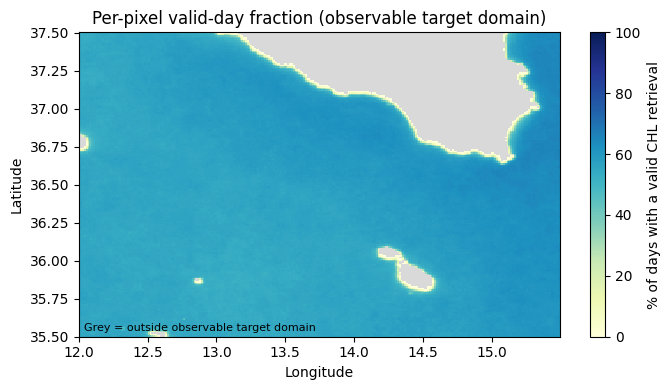

In [7]:
import matplotlib.pyplot as plt

pix_valid = (
    valid_mask
    .mean(dim="time")
    .compute()
    .where(target_domain)
)

cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#d9d9d9")

fig, ax = plt.subplots(
    figsize=(7, 4)
)

im = ax.pcolormesh(
    pix_valid.longitude,
    pix_valid.latitude,
    pix_valid * 100,
    shading="auto",
    cmap=cmap,
    vmin=0,
    vmax=100,
)

ax.set_title(
    "Per-pixel valid-day fraction "
    "(observable target domain)"
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.colorbar(
    im,
    ax=ax,
    label="% of days with a valid CHL retrieval",
)

ax.text(
    0.01,
    0.02,
    "Grey = outside observable target domain",
    transform=ax.transAxes,
    fontsize=8,
)

plt.tight_layout()

COVERAGE_MAP = (
    FIG_DIR / "02_coverage_map.png"
)

plt.savefig(
    COVERAGE_MAP,
    dpi=150,
)

plt.show()

---
## Next: `03-Covariates.ipynb`

Acquire and validate the minimal predictor set—gap-free L4 SST plus bathymetry—on the same region and period. The additional physical and optical covariates are downloaded later in Notebook 8a.
